# Visualise tomography and laminography geometry

Compare sample-fixed tomography and laminography, then inspect detector shifts
and explicit projection vectors. This example needs NumPy and Matplotlib only:
no ASTRA, CuPy, CUDA device or external dataset is required.

Volume arrays use (Z, Y, X), while the plot labels use physical XYZ coordinates.
Detector reference planes can intersect the volume in parallel-beam geometry;
the ray arrows show direction, not source distance. A final laboratory-frame
plot fixes the beam and detector while showing the tilted sample.

In [1]:
%matplotlib inline

import numpy as np
import matplotlib.pyplot as plt
from tomobar.geometry import Parallel3DGeometry, Volume3DGeometry
from tomobar.visualisation import plot_geometry

## Choose a working volume and acquisition views
Volume arrays use (Z, Y, X); plots use physical XYZ coordinates.

In [2]:
reconstruction_grid = Volume3DGeometry(shape=(24, 32, 48))
angles_rad = np.linspace(0, np.pi, 36, endpoint=False)
detector_shape = (32, 64)
view_indices = [0, 12, 24]

Compare the same volume under two beam-to-axis angles.

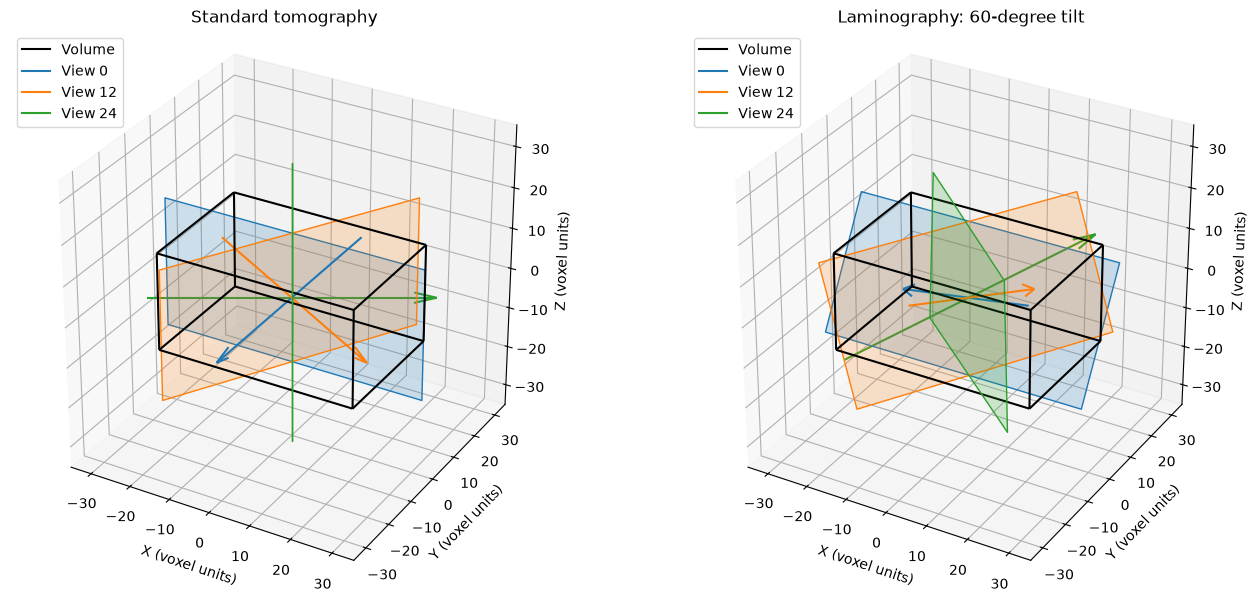

In [3]:
tomography = Parallel3DGeometry.tomography(
    angles=angles_rad, detector_shape=detector_shape, centre_of_rotation=0.0
)
laminography = Parallel3DGeometry.laminography(
    angles=angles_rad, detector_shape=detector_shape, tilt_angle=np.pi / 3
)

fig = plt.figure(figsize=(14, 6))
ax = fig.add_subplot(121, projection="3d")
plot_geometry(tomography, reconstruction_grid, view_indices=view_indices, ax=ax)
ax.set_title("Standard tomography")
ax = fig.add_subplot(122, projection="3d")
plot_geometry(laminography, reconstruction_grid, view_indices=view_indices, ax=ax)
ax.set_title("Laminography: 60-degree tilt")
plt.tight_layout()
plt.show()

Detector shifts and non-unit detector pixels use the same vector convention.

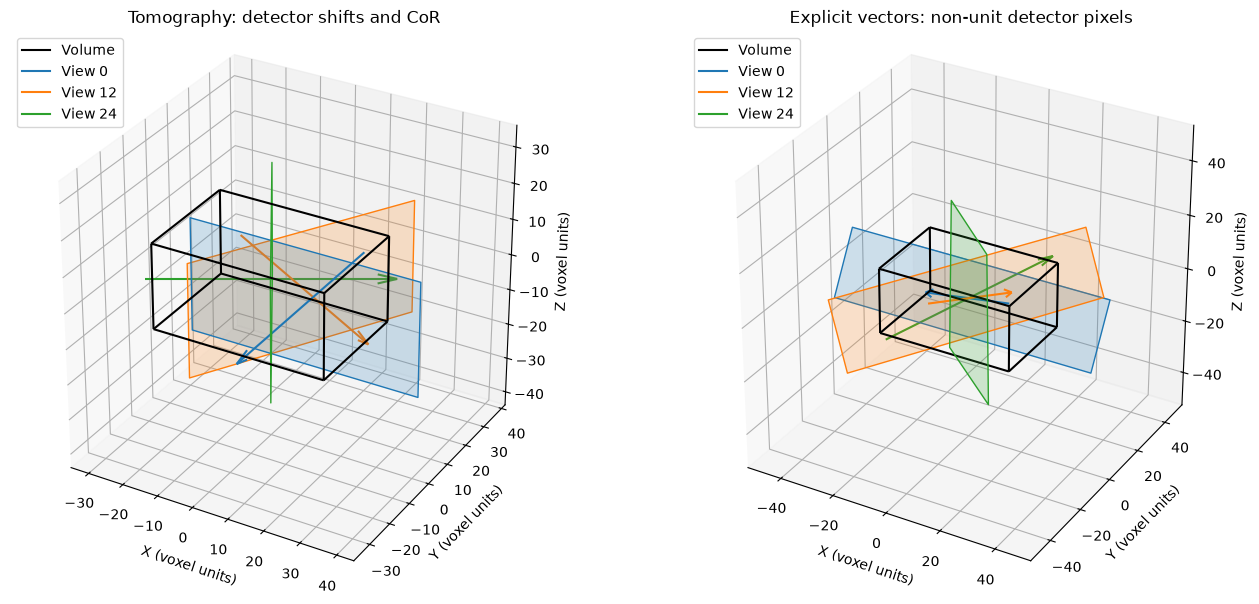

In [4]:
# Horizontal/vertical shifts and CoR are in detector pixels, applied once.
shifted_scan = Parallel3DGeometry.tomography(
    angles=angles_rad,
    detector_shape=detector_shape,
    detector_shifts=np.tile([6.0, -4.0], (len(angles_rad), 1)),
    centre_of_rotation=3.0,
)

# Explicit vectors can represent tilted detectors and non-unit pixel sizes.
vectors = laminography.to_vectors()
vectors[:, 6:9] *= 1.5  # column step: 1.5 voxel units
vectors[:, 9:12] *= 0.75  # row step: 0.75 voxel units
vector_scan = Parallel3DGeometry.from_vectors(
    vectors=vectors, detector_shape=detector_shape
)

fig = plt.figure(figsize=(14, 6))
ax = fig.add_subplot(121, projection="3d")
plot_geometry(shifted_scan, reconstruction_grid, view_indices=view_indices, ax=ax)
ax.set_title("Tomography: detector shifts and CoR")
ax = fig.add_subplot(122, projection="3d")
plot_geometry(vector_scan, reconstruction_grid, view_indices=view_indices, ax=ax)
ax.set_title("Explicit vectors: non-unit detector pixels")
plt.tight_layout()
plt.show()

## View the instrument in the laboratory frame
Here the beam and detector stay fixed. The sample rotates about its tilted
axis, and the curved arrow indicates sample motion. Detector distance is
schematic in this frame; the acquisition geometry is unchanged.

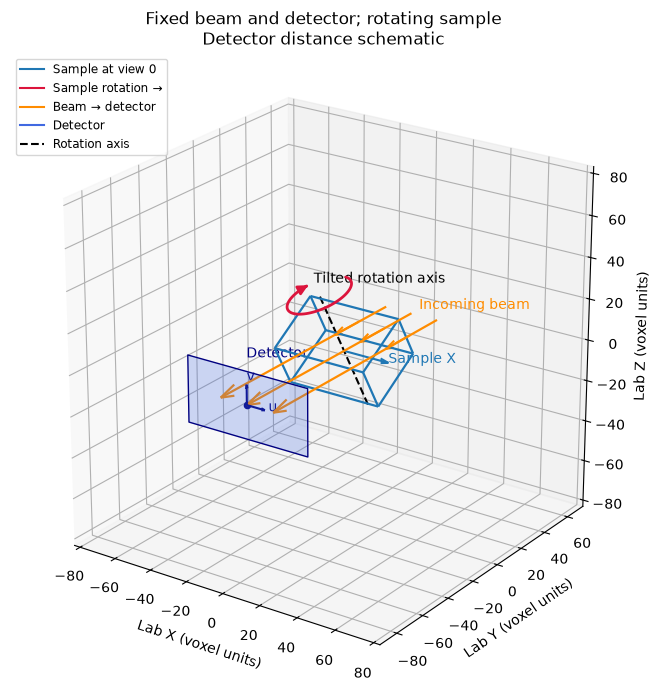

In [5]:
figure, ax = plot_geometry(
    laminography, reconstruction_grid, view_indices=[0], frame="laboratory"
)
figure.tight_layout()
plt.show()